In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
from typing import Dict, Tuple
import os
from sklearn.linear_model import LinearRegression
import sys
import pyblock
bme_dir = '/projects/lindorff_group/people/thd711/HDX_project/code/BME/' # replace this with your local copy of the BME code
sys.path.append(bme_dir)
import BME as BME

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 150,                   # medium resolution

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": False,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

# Function to calculate helical fraction
def helical_fraction(ss_line):
    helix_chars = {'H', 'G', 'I'}
    n_residues = len(ss_line)
    n_helical = sum(1 for c in ss_line if c in helix_chars)
    return n_helical / n_residues

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

outpath='./'
hyres_path = '../../IDP_REWEIGHTING/aSyn/rewM14DH_scaled/'
bioemu_path = '../../IDP_REWEIGHTING/aSyn/bioemu_M14DH_scaled/'
desres_path = '../../IDP_REWEIGHTING/aSyn/desres_M14DH_scaled/'
ensembles = ['BioEmu', 'a99SB-disp', 'HyRes']
ensemble_paths = [bioemu_path, desres_path, hyres_path]

In [8]:
# load experimental data

df = pd.read_csv(f'../../EXP_DATA/aSyn.csv')
F_exp = np.array(df['Rel. Uptake'])
# ensure all experimental values are between 0 and 1
F_exp = np.maximum(F_exp, float(0))
F_exp = np.minimum(F_exp, float(1))
print(np.min(F_exp))
print(np.max(F_exp))
sigma = np.abs(np.array(df['Rel. Uptake SD']))
times = np.array(df['Time (s)'])
peptides = []
for i in range(len(df)):
    pep_i = [idx for idx in range(int(df['Start'][i]) - 1, int(df['End'][i]))] # 0-indexed
    peptides.append(pep_i)

0.0
1.0


No handles with labels found to put in legend.


No handles with labels found to put in legend.
No handles with labels found to put in legend.


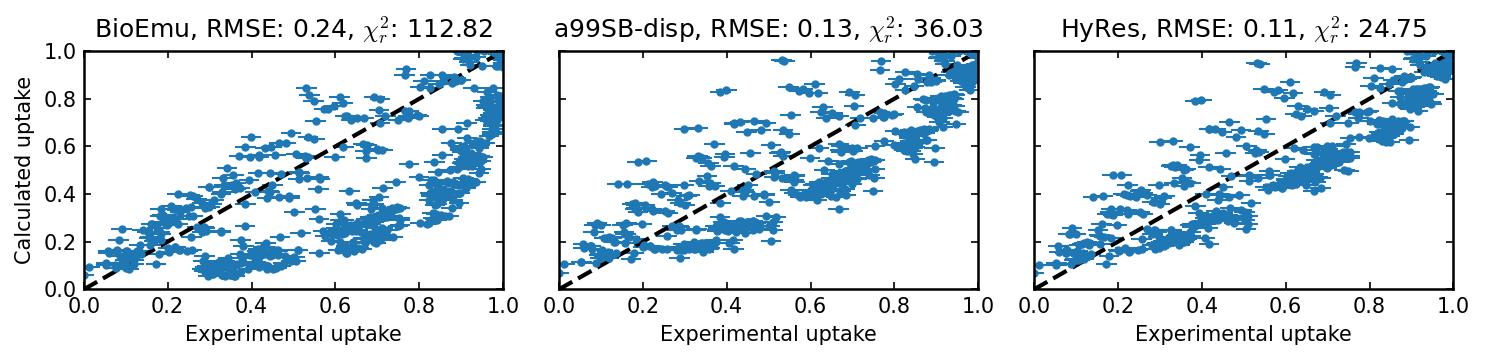

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import mdtraj as md

# comparison with secondary structure / helicity
protein = 'aSyn'
ensembles = ['BioEmu', 'a99SB-disp', 'HyRes']
ensemble_paths = [bioemu_path, desres_path, hyres_path]

all_pred_values = []
all_rmse = []
all_chi2 = []

for ensemble, path in zip(ensembles, ensemble_paths):

    if ensemble=='HyRes':
        rmse = np.loadtxt(path+"rmse.txt")[0] # prior, no reweighting
        chi2r = np.loadtxt(path+"chi2r.txt")[0] # prior, no reweighting
        pred_vals = np.load(path+"pred_uptakes.npy")[0] # prior, no reweighting
    else:
        rmse = np.loadtxt(path+"rmse.txt")
        chi2r = np.loadtxt(path+"chi2r.txt")
        pred_vals = np.load(path+"pred_uptakes.npy")[0]

    all_pred_values.append(pred_vals)
    all_rmse.append(rmse)
    all_chi2.append(chi2r)


# plot
fig, axes = plt.subplots(
    1, 3,
    figsize=(10., 2.5),
    sharex=True,
    sharey=True
)

for ax, ensemble, pred_uptake, rmse, chi2 in zip(axes, ensembles, all_pred_values, all_rmse, all_chi2):

    ax.errorbar(
        x=F_exp,
        y=pred_uptake,
        xerr = sigma,
        fmt='o',
        markersize = 3,
        capsize = 0.5,
        elinewidth= 1.,
        color = 'tab:blue'
    )

    ax.set_title(ensemble + str(f', RMSE: {rmse:.2f}, $\chi^2_r$: {chi2:.2f}'))
    ax.set_xlabel('Experimental uptake')
    ax.plot([0,1], [0,1], 'k--')
    ax.set_ylim(0,1)
    ax.set_xlim(0,1)
    ax.legend(frameon=False, fontsize=8)

axes[0].set_ylabel('Calculated uptake')

plt.tight_layout()
plt.savefig(f'HDX_plots.png')
plt.show()

In [10]:
outpath='./'
hyres_path = '../../IDP_REWEIGHTING/aSyn/rewM14DH/'
bioemu_path = '../../IDP_REWEIGHTING/aSyn/bioemu_M14DH/'
desres_path = '../../IDP_REWEIGHTING/aSyn/desres_M14DH/'
ensembles = ['BioEmu', 'a99SB-disp', 'HyRes']
ensemble_paths = [bioemu_path, desres_path, hyres_path]

No handles with labels found to put in legend.
No handles with labels found to put in legend.


No handles with labels found to put in legend.


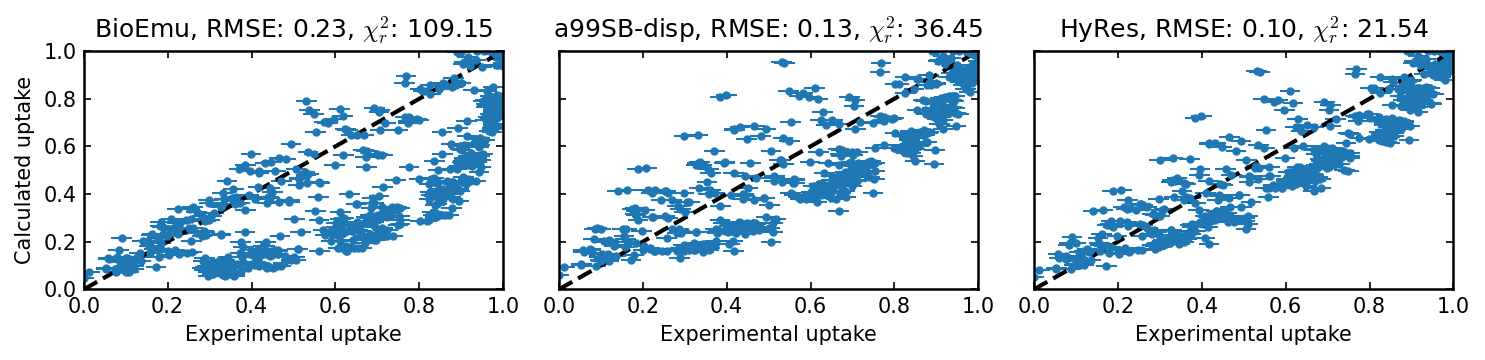

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import mdtraj as md

# comparison with secondary structure / helicity
protein = 'aSyn'
ensembles = ['BioEmu', 'a99SB-disp', 'HyRes']
ensemble_paths = [bioemu_path, desres_path, hyres_path]

all_pred_values = []
all_rmse = []
all_chi2 = []

for ensemble, path in zip(ensembles, ensemble_paths):

    if ensemble=='HyRes':
        rmse = np.loadtxt(path+"rmse.txt")[0] # prior, no reweighting
        chi2r = np.loadtxt(path+"chi2r.txt")[0] # prior, no reweighting
        pred_vals = np.load(path+"pred_uptakes.npy")[0] # prior, no reweighting
    else:
        rmse = np.loadtxt(path+"rmse.txt")
        chi2r = np.loadtxt(path+"chi2r.txt")
        pred_vals = np.load(path+"pred_uptakes.npy")[0]

    all_pred_values.append(pred_vals)
    all_rmse.append(rmse)
    all_chi2.append(chi2r)


# plot
fig, axes = plt.subplots(
    1, 3,
    figsize=(10., 2.5),
    sharex=True,
    sharey=True
)

for ax, ensemble, pred_uptake, rmse, chi2 in zip(axes, ensembles, all_pred_values, all_rmse, all_chi2):

    ax.errorbar(
        x=F_exp,
        y=pred_uptake,
        xerr = sigma,
        fmt='o',
        markersize = 3,
        capsize = 0.5,
        elinewidth= 1.,
        color = 'tab:blue'
    )

    ax.set_title(ensemble + str(f', RMSE: {rmse:.2f}, $\chi^2_r$: {chi2:.2f}'))
    ax.set_xlabel('Experimental uptake')
    ax.plot([0,1], [0,1], 'k--')
    ax.set_ylim(0,1)
    ax.set_xlim(0,1)
    ax.legend(frameon=False, fontsize=8)

axes[0].set_ylabel('Calculated uptake')

plt.tight_layout()
plt.savefig(f'HDX_plots_M14DH.png')
plt.show()